# 07-02 - Fifteen Minutes on Foot

You rerun the lecture's second chapter on Princeton's data, from the toy by hand to the 15-minute city, the minutes to Princeton Junction and who can reach what.

First the places and the lecture's toy by hand, then isochrones from your own start, P01's duel and the two accessibility measures over the 839 cells. Then the 15-minute city, every cell to Princeton Junction, the Dinky minute by minute and who can reach what. At the end you change the budget.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mob_tools as mob

plt.rcParams["figure.dpi"] = 72

scene = json.load(open("data/scene.json"))
reference = json.load(open("data/ground_truth.json"))["p07"]
rules, anchors, lecture = scene["rules"], scene["anchors"], scene["lecture"]
print(f"Princeton's networks of {scene['snapshot']['graphs']} through osmnx {scene['snapshot']['osmnx']} in "
      f"{scene['crs']}; the specimen {reference['traces']['kp2']['fixes']:,} fixes; the stay rule "
      f"{rules['stay']['dist_m']:g} m and {rules['stay']['min_s'] / 60:g} minutes; the class's counts are "
      f"{'published' if reference['class_traces']['published'] else 'not published yet'}")

Princeton's networks of 2026-10-30 through osmnx 2.1.1 in EPSG:26918; the specimen 8,918 fixes; the stay rule 50 m and 10 minutes; the class's counts are not published yet


## The places, the cells, the block groups

The cell reads the destinations, the cells with their residents and the walk network, snaps the places to eat to the network and draws every place over the residents.

293 destinations: transit 129, food 92, park 26, school 25, grocery 11, library 6, pharmacy 4
839 cells of 250 m holding 30,756 residents from 21 block groups   reference 30,756 residents


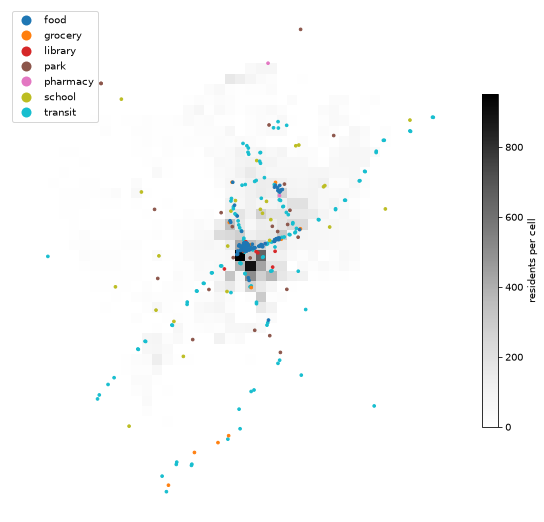

In [2]:
dest = gpd.read_file("data/layers.gpkg", layer="destinations")
grid = gpd.read_file("data/layers.gpkg", layer="grid")
walk = mob.load_graph("data/princeton_walk.graphml")
kind = dest["category"].replace({"bus_stop": "transit", "station": "transit"}).to_numpy()
food = dest[kind == "food"]
food_nodes = mob.nearest_nodes(walk, food.geometry.x.to_numpy(), food.geometry.y.to_numpy())
fig, ax = plt.subplots(figsize=(10, 10))
mob.show_access(grid, grid["population"], ax, cmap="Greys", label="residents per cell")
dest.assign(kind=kind).plot(ax=ax, column="kind", markersize=7, legend=True)
print(f"{len(dest)} destinations:", ", ".join(f"{k} {n}" for k, n in pd.Series(kind).value_counts().items()))
print(f"{len(grid)} cells of {rules['grid_m']:.0f} m holding {grid['population'].sum():,.0f} residents from "
      f"{grid['GEOID'].nunique()} block groups   reference {reference['access']['residents']:,.0f} residents")

Accessibility needs the network of 07-01 and two things more, the places where the opportunities are and a speed or a schedule that turns metres into minutes. The destinations come from OpenStreetMap and the P02 food places. Bus stops and stations count as transit, which gives the lecture's six kinds, and the libraries count only in Hansen's score. The residents are the block groups' population spread over the cells by built area, since a block group's population is known and a cell's is not.

## Seven places by hand

The cell builds the lecture's toy, seven places joined by nine paths with lengths in hundreds of metres, and works its isochrone and both measures at A.

In [3]:
toy = mob.graph_from_edges(lecture["toy"]["edges"], lecture["toy"]["layout"], unit=lecture["toy"]["unit_m"])
dist, rt = dict(sorted(mob.times_from(toy, ["A"], weight="length").items())), reference["access"]["toy"]
part = {u + v: (400 - min(dist[u], dist[v])) / toy[u][v]["length"] for u, v in toy.edges()
        if min(dist[u], dist[v]) < 400 < max(dist[u], dist[v])}
metres, eat = np.array([list(dist.values())]), np.array([lecture["toy"]["food"][n] for n in dist])
print("metres from A along the paths: " + ", ".join(f"{n} {d:.0f}" for n, d in dist.items()))
print("within 400 m whole " + ", ".join(n for n, d in dist.items() if d <= 400) + ", in part "
      + ", ".join(f"{e} {s:.2f}" for e, s in part.items()) + "   reference " + ", ".join(rt["reached_400"])
      + ", " + ", ".join(f"{e} {s:.2f}" for e, s in rt["partial_400"].items()))
print(f"places to eat within 400 m {mob.cumulative(metres, eat, threshold=400)[0]:.0f}, Hansen's score at A "
      f"{mob.hansen(metres, eat, beta=1 / 500)[0]:.2f}   reference "
      f"{rt['cumulative_400']}, {rt['hansen']:.2f}")

metres from A along the paths: A 0, B 200, C 300, D 500, E 500, F 800, G 900
within 400 m whole A, B, C, in part BD 0.67, CE 0.50   reference A, B, C, BD 0.67, CE 0.50
places to eat within 400 m 3, Hansen's score at A 3.69   reference 3, 3.69


Every number here is on the lecture's slides. From A an isochrone of 400 m keeps A, B and C whole and runs two thirds of the way along BD and half way along CE, the budget left over the edge's length. The cumulative measure counts the places to eat at the nodes within 400 m. Hansen's score weights each place by exp of minus its distance over 500 m, so B's two places at 200 m count 2 times 0.67, and sums.

## An isochrone from your own start

The cell snaps a start to the walk network, finds every node within 5, 10 and 15 minutes, buffers the edges with both ends reached and counts places to eat.

 5 minutes   31 ha, 44 places to eat   reference   31 ha, 44
10 minutes  117 ha, 64 places to eat   reference  117 ha, 64
15 minutes  239 ha, 77 places to eat   reference  239 ha, 77


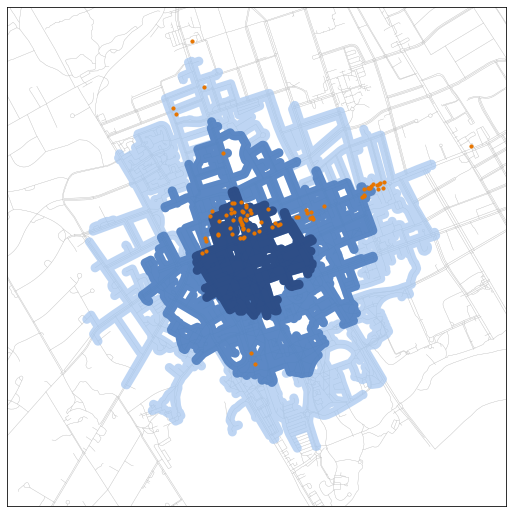

In [4]:
sx, sy = map(float, mob.project(-74.659271, 40.348769))  # Nassau Hall; your own lon and lat here
reached = {m: mob.isochrone(walk, mob.nearest_nodes(walk, sx, sy), m) for m in rules["iso_minutes"]}
polys = [mob.isochrone_polygon(walk, r, buffer_m=25.0) for r in reached.values()]
riso = reference["access"]["isochrones"]
fig, ax = plt.subplots(figsize=(9, 9))
mob.show_graph(walk, ax, colour="#cccccc", lw=0.3)
mob.show_isochrones(polys, ax, ["#1f3b73", "#3b6fb6", "#a8c8f0"])
food.plot(ax=ax, color="#e77500", markersize=10, zorder=3)
ax.set(xlim=(sx - 1400, sx + 1400), ylim=(sy - 1400, sy + 1400), xticks=[], yticks=[])
for (m, r), poly in zip(reached.items(), polys):
    print(f"{m:2d} minutes {poly.area / 1e4:4.0f} ha, {sum(n in r for n in food_nodes):2d} places to eat"
          f"   reference {riso[f'walk_{m}']['area_ha']:4.0f} ha, {riso[f'walk_{m}']['food']:2d}")

An isochrone is the set of places reachable within a budget along the network. At 4.8 km/h a minute is 80 m, so fifteen minutes reach 1.2 km. The area is every edge with both ends reached, buffered by 25 m, darkest for five minutes, and an orange place to eat counts when its nearest node was reached. From Nassau Hall the shape follows the campus paths south and Nassau Street east and west. The reference is Nassau Hall's; your own longitude and latitude go on the first line.

## Three modes, one budget

The cell loads the bicycle and drive networks, draws fifteen minutes from the same start on each graph, and the circle a straight-line budget would draw.

drive 92 places to eat in 15 minutes   reference 92


bike  92 places to eat in 15 minutes   reference 92


walk  77 places to eat in 15 minutes   reference 77
the circle of 1.2 km covers 1.9 times the walk's area   reference 1.9


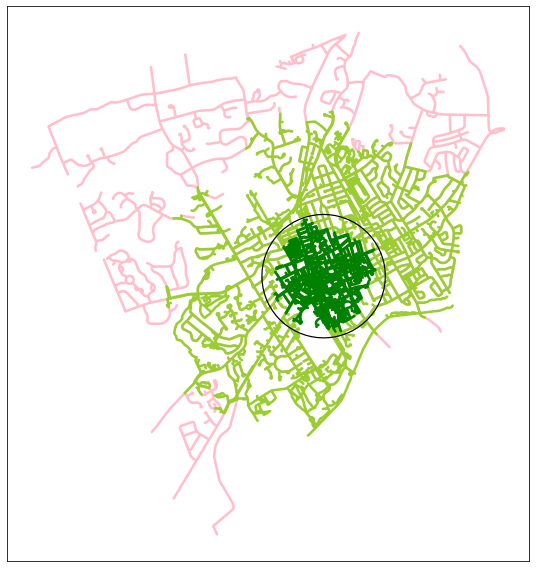

In [5]:
bike = mob.load_graph("data/princeton_bike.graphml")
drive = mob.load_graph("data/princeton_drive.graphml")
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"xticks": [], "yticks": []})
for mode, graph in (("drive", drive), ("bike", bike), ("walk", walk)):
    hit = mob.isochrone(graph, mob.nearest_nodes(graph, sx, sy), rules["budget_min"])
    area = mob.isochrone_polygon(graph, hit, buffer_m=25.0)
    n_food = sum(n in hit for n in mob.nearest_nodes(graph, food.geometry.x, food.geometry.y))
    gpd.GeoSeries([area]).plot(ax=ax, color={"drive": "pink", "bike": "yellowgreen", "walk": "green"}[mode])
    print(f"{mode:5s} {n_food:2d} places to eat in 15 minutes   reference {riso[f'{mode}_15']['food']:2d}")
gpd.GeoSeries([mob.circle((sx, sy), 1200.0).boundary]).plot(ax=ax, color="#000000", lw=1.2)
print(f"the circle of 1.2 km covers {np.pi * 1200 ** 2 / polys[-1].area:.1f} times the walk's area   "
      f"reference {riso['circle_1200']['ratio_to_walk_15']:.1f}")

Each area comes from its own graph with its own edges and speeds, pink for the car at the posted limits, light green for the bicycle at 15 km/h and dark green for the walk. The three are different networks read with one budget, not nested versions of one network. From Nassau Hall the bicycle and the car both reach 92 places to eat. The black ring is the circle of 1.2 km, which covers about twice the walk's area, the lie of the circle once more.

## The duel of P01, once more

The cell counts the places to eat within 400 m of E225 by a circle and along the walk network of the whole town, and draws both.

within 400 m of E225 20 places to eat by the circle, 3 along the paths   reference 20 and 3


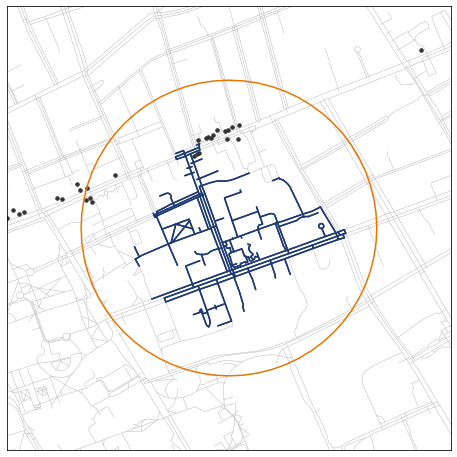

In [6]:
ex, ey = map(float, mob.project(anchors["e225"]["lon"], anchors["e225"]["lat"]))
reached_400 = mob.isochrone(walk, mob.nearest_nodes(walk, ex, ey), 400.0 / 80.0)
by_circle = int(food.within(mob.circle((ex, ey), 400.0)).sum())
by_network = sum(n in reached_400 for n in food_nodes)
fig, ax = plt.subplots(figsize=(8, 8))
mob.show_graph(walk, ax, colour="#cccccc", lw=0.4)
mob.show_graph(walk.subgraph(reached_400), ax, colour="#1f3b73", lw=1.5)
gpd.GeoSeries([mob.circle((ex, ey), 400.0).boundary]).plot(ax=ax, color="#e77500", lw=1.5)
food.plot(ax=ax, color="#333333", markersize=12)
ax.set(xlim=(ex - 600, ex + 600), ylim=(ey - 600, ey + 600), xticks=[], yticks=[])
print(f"within 400 m of E225 {by_circle} places to eat by the circle, {by_network} along the paths"
      f"   reference {reference['access']['duel']['circle']} and {reference['access']['duel']['network']}")

In the first precept a circle of 400 m around E225 held twenty places to eat. Along the paths of the whole town the same 400 m reach three, because a walk goes around the buildings and blocks that the circle crosses. The dark lines are the paths reached and the orange ring is the circle. The second count is the one a person walking to lunch experiences, and where the two disagree is where the map lies.

## Two measures over the 839 cells

The cell computes the minutes on foot from every cell's centre to every destination, counts the grocery stores within fifteen minutes, sums Hansen's score and maps both.

grocery stores within 15 minutes, up to 4, none in 680 cells; Hansen's weight 0.37 at 10 minutes, 0.05 at 30   reference 4, 680, 0.37, 0.05


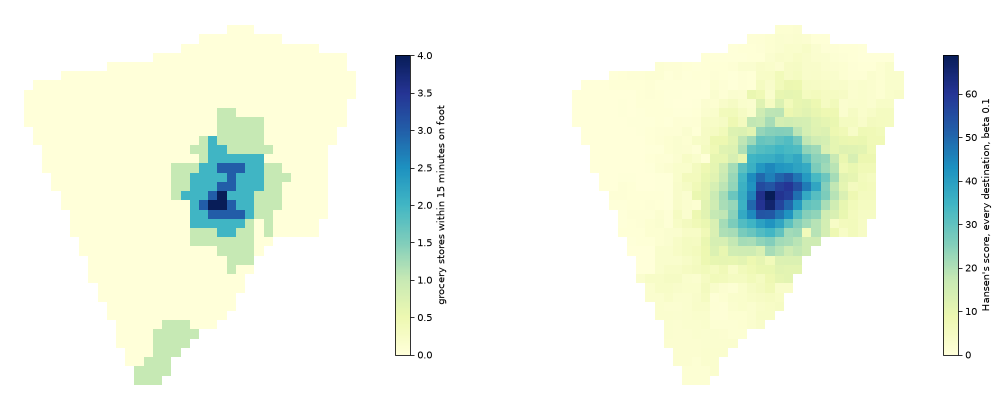

In [7]:
cell_nodes = mob.nearest_nodes(walk, grid.geometry.centroid.x, grid.geometry.centroid.y)
place_nodes = mob.nearest_nodes(walk, dest.geometry.x, dest.geometry.y)
M = mob.travel_time_matrix(walk, cell_nodes, place_nodes, cutoff_min=rules["matrix_cutoff_min"])
count15 = mob.cumulative(M[:, kind == "grocery"], threshold=rules["budget_min"])
rh, rg, beta = reference["access"]["hansen"], reference["access"]["grocery_count15"], rules["hansen_beta"]
hansen = mob.hansen(M, beta=beta)
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
mob.show_access(grid, count15, axes[0], cmap="YlGnBu", label="grocery stores within 15 minutes on foot")
mob.show_access(grid, hansen, axes[1], cmap="YlGnBu", label="Hansen's score, every destination, beta 0.1")
print(f"grocery stores within 15 minutes, up to {count15.max():.0f}, none in {(count15 == 0).sum()} cells; "
      f"Hansen's weight {np.exp(-beta * 10):.2f} at 10 minutes, {np.exp(-beta * 30):.2f} at 30   reference "
      f"{rg['max']}, {rg['cells_zero']}, {rh['weight_10']:.2f}, {rh['weight_30']:.2f}")

Cumulative opportunities count what lies within a budget, up to four grocery stores in the central blocks and none in most of the town. Hansen's gravity-based measure weights every destination by exp of minus a tenth of its minutes, so a shop ten minutes away counts 0.37 and one thirty minutes away 0.05. The maps agree on the downtown and disagree at the edges, where one far store makes the count one and the score small. The count has a cliff at the budget, the score a decay to choose.

## A grocery store by four modes

The cell finds every cell's nearest place of each kind on the walk, bicycle and drive networks, adds the lecture's transit minutes and weights the cells by residents.

In [8]:
pop, cent = grid["population"].to_numpy(), grid.geometry.centroid
near = {}
for mode, graph in (("walk", walk), ("bike", bike), ("drive", drive)):
    targets = np.array(mob.nearest_nodes(graph, dest.geometry.x, dest.geometry.y))
    origins = mob.nearest_nodes(graph, cent.x, cent.y)
    near[mode] = mob.nearest_times(graph, origins, {k: targets[kind == k].tolist() for k in rules["six"]})
transit_min = pd.read_csv("data/access_cells.csv.gz")["transit_grocery_min"].to_numpy()
grocery = {"walk": near["walk"]["grocery"], "bike": near["bike"]["grocery"], "transit": transit_min,
           "drive": near["drive"]["grocery"]}
shares = {mode: mob.share_within(minutes, pop, 15.0) for mode, minutes in grocery.items()}
print("residents within 15 minutes of a grocery store " + ", ".join(f"{m} {s:.0%}" for m, s in shares.items())
      + "   reference " + ", ".join(f"{reference['access']['share_grocery_15'][m]:.0%}" for m in shares))

residents within 15 minutes of a grocery store walk 64%, bike 94%, transit 54%, drive 100%   reference 64%, 94%, 54%, 100%


The lecture opened with this table. Each mode has its own graph and speed, the walk 4.8 km/h, the bicycle 15 km/h and the car the posted limits, the Friday afternoon of nobody. The transit minutes come from the lecture's run of r5py over the NJ Transit schedule, leaving between 8 and 9 on a Monday, shipped because the router is not in the environment. On foot the share is small for a walkable town, because the stores sit on two corridors and the houses do not.

## The 15-minute city, measured

The cell counts how many of the six kinds each cell reaches within fifteen minutes on foot and by bicycle, and outlines the cells that reach all six.

walk: 43% in 67 cells reach all six, lowest pharmacy 49%   reference 43%, 67, pharmacy 49%
bike: 90% in 483 cells reach all six, lowest pharmacy 91%   reference 90%, 483, pharmacy 91%


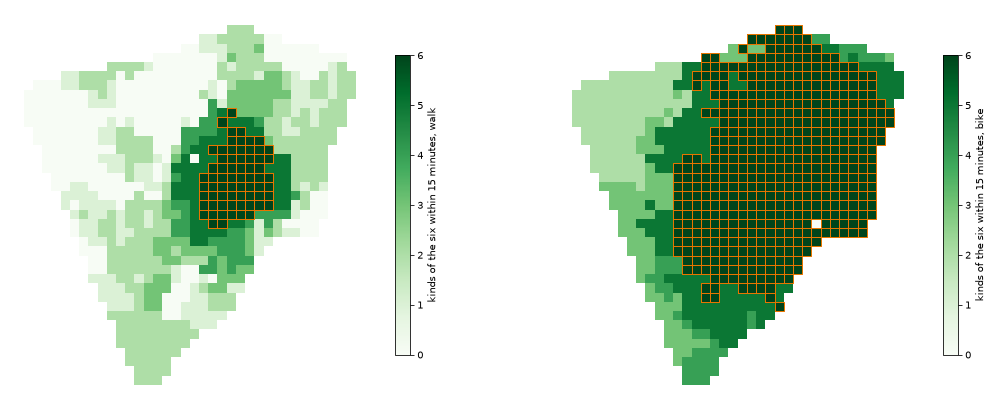

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, mode in zip(axes, ("walk", "bike")):
    within = near[mode][rules["six"]].to_numpy() <= rules["budget_min"]
    all_six, ra = within.all(axis=1), reference["access"]["all_six"][mode]
    share = dict(zip(rules["six"], np.average(within, axis=0, weights=pop)))
    low = min(share, key=share.get)
    mob.show_access(grid, within.sum(axis=1), ax, cmap="Greens", vmin=0, vmax=6,
                    label=f"kinds of the six within 15 minutes, {mode}")
    grid[all_six].boundary.plot(ax=ax, color="#e77500", lw=1)
    print(f"{mode}: {pop[all_six].sum() / pop.sum():.0%} in {all_six.sum()} cells reach all six, lowest "
          f"{low} {share[low]:.0%}   reference {ra['share']:.0%}, {ra['cells']}, {ra['lowest']} "
          f"{ra['by_type'][ra['lowest']]:.0%}")

Moreno's 15-minute city is a claim about proximity, that the six functions of daily life should lie within a quarter of an hour on foot or by bicycle. Weighted by the residents each cell holds, under half of the town's people live in a cell that passes on foot and nine in ten by bicycle; the orange outlines mark those cells. The downtown passes on every count and the edges do not, and on foot the kind fewest residents reach is the pharmacy, of which the town has four.

## Every cell to Princeton Junction

The cell reads the router's minutes from every cell to the stop at Princeton Junction on foot, by transit and by car, and maps the three on one scale.

walk     89 minutes from the cell of Nassau Hall,   0% of residents within 30   reference  89,   0%
transit  30 minutes from the cell of Nassau Hall,  19% of residents within 30   reference  30,  19%
car      11 minutes from the cell of Nassau Hall, 100% of residents within 30   reference  11, 100%


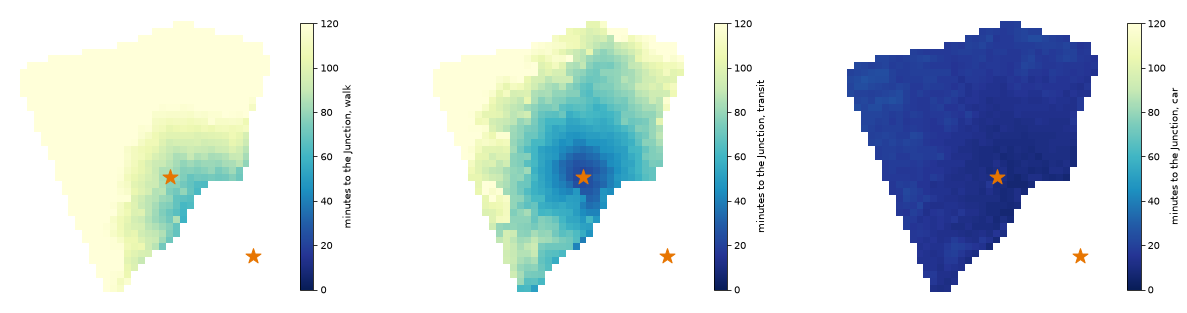

In [10]:
jc = pd.read_csv("data/junction_cells.csv.gz").set_index("cell").reindex(range(len(grid)))
dinky = json.load(open("data/dinky.json"))
stops = pd.DataFrame(dinky["stops"]).T[["x", "y"]].astype(float)
here, rj = jc.loc[anchors["nassau_cell"]], reference["access"]["transit"]
fig, axes = plt.subplots(1, 3, figsize=(21, 8))
for ax, mode, col in zip(axes, ("walk", "transit", "car"), ("walk_min", "transit_p50", "car_min")):
    within30 = mob.share_within(jc[col], pop, 30.0)
    mob.show_access(grid, jc[col].fillna(999), ax, vmin=0, vmax=120, label=f"minutes to the Junction, {mode}")
    ax.scatter(stops["x"], stops["y"], marker="*", s=250, color="#e77500")
    print(f"{mode:7s} {here[col]:3.0f} minutes from the cell of Nassau Hall, {within30:4.0%} of residents "
          f"within 30   reference {rj[col]:3.0f}, {rj['share30'][mode]:4.0%}")

The lecture's run of r5py routed every cell to the station's stop three times, leaving between 8 and 9 on Monday 2 November. On foot it walks at 3.6 km/h, slower than the walk network's 4.8, and by transit it takes the fastest mix of walking, buses and the Dinky for each of the 60 departure minutes and reports their median. The stars are the Dinky's two stations. The transit map is a map of the walk to the Princeton station rather than of the distance to the Junction.

## The walk to the Dinky

The cell reads the spread of the hour at the cell of Nassau Hall and finds where the residents live who reach the Junction within 30 minutes by transit.

by transit 22 to 38 minutes, the hour's 10th and 90th percentiles from the cell of Nassau Hall   reference 22 to 38
100% of the residents within 30 minutes by transit live within 1 km of the Dinky's Princeton stop   reference 100%


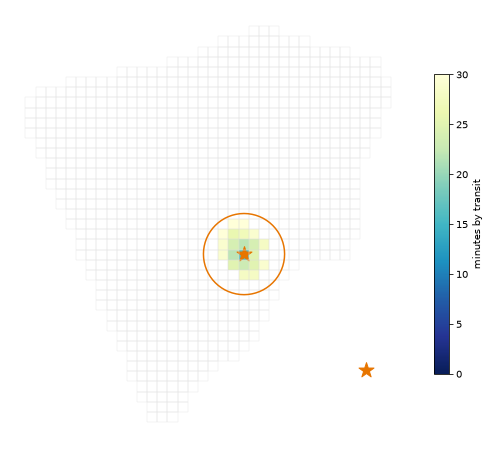

In [11]:
px, py = stops.loc["princeton"]
fast = jc["transit_p50"].to_numpy() <= 30
near_stop = np.hypot(cent.x - px, cent.y - py).to_numpy() <= 1000
fig, ax = plt.subplots(figsize=(9, 9))
grid.boundary.plot(ax=ax, color="#dddddd", lw=0.3)
mob.show_access(grid, jc["transit_p50"].where(fast), ax, vmin=0, vmax=30, label="minutes by transit")
gpd.GeoSeries([mob.circle((px, py), 1000.0).boundary]).plot(ax=ax, color="#e77500")
ax.scatter(stops["x"], stops["y"], marker="*", s=250, color="#e77500")
print(f"by transit {here['transit_p10']:.0f} to {here['transit_p90']:.0f} minutes, the hour's 10th and 90th "
      f"percentiles from the cell of Nassau Hall   reference {rj['transit_p10']} to {rj['transit_p90']}")
print(f"{pop[fast & near_stop].sum() / pop[fast].sum():.0%} of the residents within 30 minutes by transit "
      f"live within 1 km of the Dinky's Princeton stop   reference {rj['fast_near_station']:.0%}")

The median hides the minute. From the cell of Nassau Hall the 10th and 90th percentiles lie eight minutes either side of it, because the wait depends on when you leave. Every resident who reaches the Junction within 30 minutes by transit lives inside the orange circle, a kilometre around the Dinky's Princeton station, so transit here means the walk to the Dinky. The rail feed of 17 September 2026 is part of the result, since a schedule changes several times a year.

## The Dinky, minute by minute

The cell reads the Dinky's timetable, applies the next-train rule to every departure minute from 6:00 to 10:30, checks it against the router and draws walk, wait and ride.

94 trips, 47 each way   reference 94, 47
the first train 16 minutes after leaving gives the router's minutes at 271 of 271   reference 271 of 271


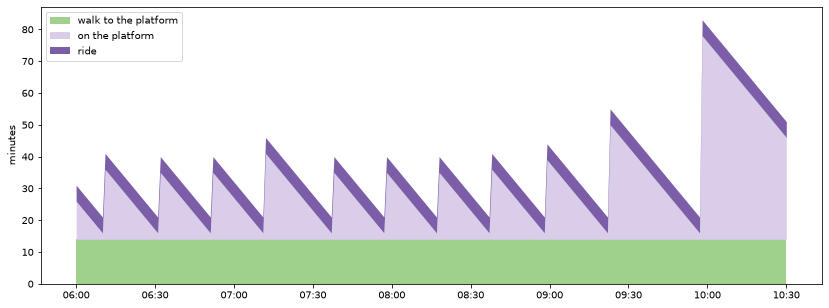

In [12]:
deps = [trip[2] for trip in dinky["trips"] if trip[1] == dinky["stops"]["junction"]["name"]]
door = mob.next_departure(deps, dinky["minutes"]["minute"], dinky["access_min"], dinky["ride_min"])
door.index, rd = door["leave"].to_numpy(), reference["access"]["dinky"]
door["walk to the platform"], door["ride"] = dinky["walk_leg_min"], dinky["ride_min"]
door["on the platform"] = door["total"] - door["walk to the platform"] - door["ride"]
bands = door[["walk to the platform", "on the platform", "ride"]]
ax = bands.plot.area(figsize=(14, 5), lw=0, ylabel="minutes", color=["#9fd08c", "#d9cdea", "#7b5ea7"])
ax.set_xticks(door.index[::30], [mob.clock(m * 60) for m in door.index[::30]])
print(f"{len(dinky['trips'])} trips, {len(deps)} each way   reference {rd['trips']}, {rd['each_way']}")
print(f"the first train {dinky['access_min']} minutes after leaving gives the router's minutes at "
      f"{np.isclose(door['total'], dinky['minutes']['rail_min']).sum()} of {len(door)}   reference "
      f"{rd['matches']} of {rd['minutes']}")

A schedule makes the network change with the clock, since an edge exists only while a train runs. The Dinky shuttles between two stations 4.3 km apart in 5 minutes, every 20 minutes each way in the morning, timed to meet the trains to New York. Taking the first train 16 minutes after leaving, the walk of 14 and the router's minute on the platform rounded up, reproduces the router at every minute. The walk and the ride never change, and only the time on the platform does.

## Reading the saw tooth

The cell reads the morning off the rule, the traveller who leaves at 8:00, the hour from 8 to 9 and the worst minute between 7 and 10.

In [13]:
t8, hour = door.loc[480], door.loc[480:539]
late = door.loc[door.loc[420:600, "total"].idxmax()]
new_york = min(d for d in dinky["new_york_dep_min"] if d > t8["arrive"])
print(f"leave 08:00, the {mob.clock(t8['train'] * 60)} arrives at {mob.clock(t8['arrive'] * 60)} for the "
      f"{mob.clock(new_york * 60)} to New York   reference {rd['example']['train']}, "
      f"{rd['example']['arrive']}, {rd['example']['new_york']}")
print(f"8 to 9 the trip takes {hour['total'].min():.0f} to {hour['total'].max():.0f} minutes, median "
      f"{hour['total'].median():g}, mean wait {hour['wait'].mean():.1f}   reference {rd['hour']['min']:.0f}"
      f" to {rd['hour']['max']:.0f}, {rd['hour']['median']:g}, {rd['hour']['mean_wait']:.1f}")
print(f"leaving at {mob.clock(late.name * 60)} costs {late['total']:.0f} minutes, the next train leaves at "
      f"{mob.clock(late['train'] * 60)} after the {mob.clock(deps[deps.index(late['train']) - 1] * 60)}"
      f"   reference {rd['worst']['minutes']:.0f}, {rd['worst']['next']}, {rd['worst']['missed']}")

leave 08:00, the 08:33 arrives at 08:38 for the 08:44 to New York   reference 08:33, 08:38, 08:44
8 to 9 the trip takes 21 to 44 minutes, median 30.5, mean wait 9.6   reference 21 to 44, 30.5, 9.6
leaving at 09:58 costs 83 minutes, the next train leaves at 11:16 after the 10:13   reference 83, 11:16, 10:13


Leave just after a train and the wait is a whole headway; leave just before one and it is almost nothing. So the curve falls by a minute for every minute of delay and jumps at every departure, and a walker who reaches the platform at a random moment waits about half a headway. After the morning peak the teeth grow. A schedule is a promise, not a record, and GTFS Realtime reports how late each trip actually runs.

## Who can reach what

The cell averages Hansen's score over each block group's residents, plots it against the median household income and draws the Lorenz curve across residents with its Gini.

Gini 0.42, income against accessibility -0.59 over 17 block groups   reference 0.42, -0.59 over 17


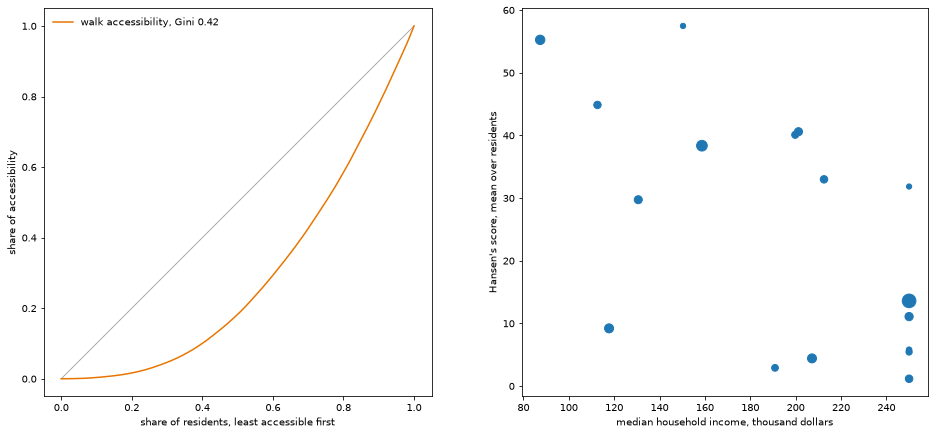

In [14]:
bg = gpd.read_file("data/layers.gpkg", layer="block_groups")
per_bg = mob.block_group_means(grid["GEOID"], pop, hansen).rename(columns={"mean": "hansen"})
fb = bg.merge(per_bg, on="GEOID", suffixes=("_acs", ""))
rf = reference["access"]["fairness"]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
gini = mob.show_lorenz(hansen, pop, axes[0], label="walk accessibility")
axes[1].scatter(fb["median_income"] / 1e3, fb["hansen"], s=fb["population"] / 20)
axes[1].set(xlabel="median household income, thousand dollars", ylabel="Hansen's score, mean over residents")
print(f"Gini {gini:.2f}, income against accessibility {fb['median_income'].corr(fb['hansen']):.2f} over "
      f"{fb['median_income'].notna().sum()} block groups   reference {rf['gini_walk_hansen']:.2f}, "
      f"{rf['pearson_income_hansen']:.2f} over {rf['block_groups_with_income']}")

Accessibility of a place becomes accessibility of a person when the cell's score is given to each of its residents, and the town's accessibility is then a distribution across people rather than a map. The Lorenz curve sorts residents from the least to the most accessible against the share of accessibility they hold, and the Gini is twice the area between the curve and the diagonal. Four block groups report no income. The relation with income is negative, and the downtown block groups that walk the most reach the most.

## Who depends on the bus

The cell maps the share of households without a car by block group and plots it against the median of the block group's transit minutes to the Junction.

no car in 12% of the households   reference 12%; in the 20 block groups with households the median transit minutes run from 27 to 113   reference 27 to 113


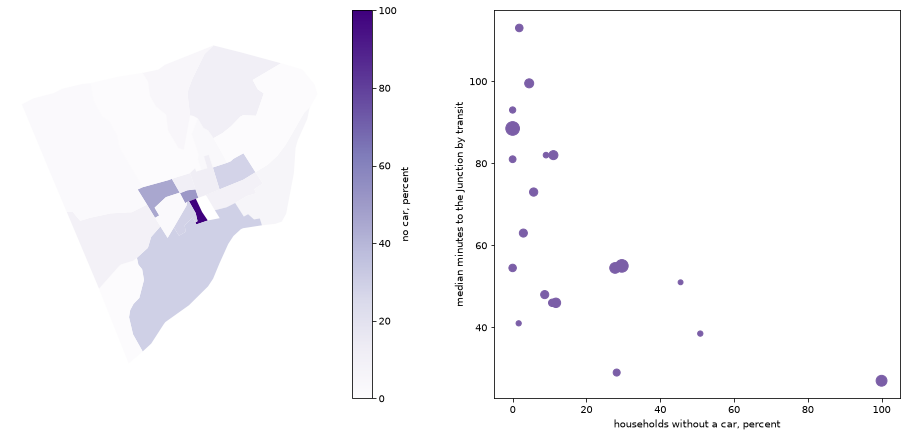

In [15]:
fb["no_car"] = 100 * fb["no_vehicle"] / fb["households"]
fb["junction"] = fb["GEOID"].map(jc["transit_p50"].groupby(grid["GEOID"].to_numpy()).median())
drawn = fb.dropna(subset=["no_car", "junction"])
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fb.plot(column="no_car", ax=axes[0], cmap="Purples", legend=True, legend_kwds={"label": "no car, percent"})
axes[0].set_axis_off()
axes[1].scatter(drawn["no_car"], drawn["junction"], s=drawn["population"] / 20, color="#7b5ea7")
axes[1].set(xlabel="households without a car, percent", ylabel="median minutes to the Junction by transit")
print(f"no car in {fb['no_vehicle'].sum() / fb['households'].sum():.0%} of the households   reference "
      f"{rf['no_vehicle_share']:.0%}; in the {len(drawn)} block groups with households the median "
      f"transit minutes run from {drawn['junction'].min():.0f} to {drawn['junction'].max():.0f}   reference "
      f"{rf['transit_junction']['min']:.0f} to {rf['transit_junction']['max']:.0f}")

The fairness question is a comparison of two distributions, not a map. The households without a car live mostly on the campus and downtown, where students and older residents walk, and the scatter asks who depends on the bus and how well the bus serves them. The block group without households has no share and drops out. Two of the pitched projects live on this picture, and both need a network, a schedule, a measure and the census.

## Your turn

The 15-minute city was measured with a budget of fifteen minutes. Measure the 10-minute city instead, on foot and by bicycle, and compare every kind of place's share of residents at the two budgets. Run the cell as it is, then change the marked value and run it again.

Which kind of place loses the most residents when the budget drops to ten minutes, and why that one? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

walk, 15 minutes: 43% reach all six; food 66%, grocery 64%, pharmacy 49%, school 77%, park 71%, transit 86%
bike, 15 minutes: 90% reach all six; food 94%, grocery 94%, pharmacy 91%, school 98%, park 100%, transit 98%


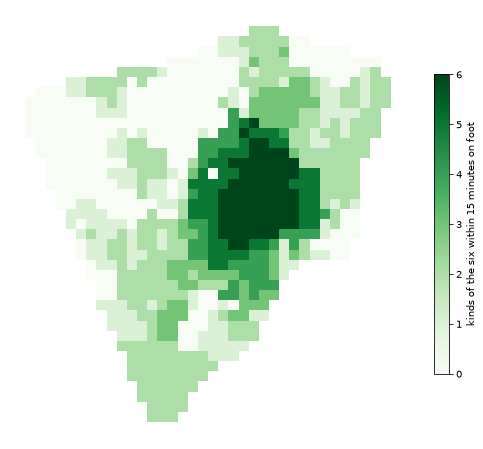

In [16]:
MINUTES = 15  # change me: 10
fig, ax = plt.subplots(figsize=(9, 9))
mob.show_access(grid, (near["walk"][rules["six"]].to_numpy() <= MINUTES).sum(axis=1), ax, cmap="Greens",
                vmin=0, vmax=6, label=f"kinds of the six within {MINUTES} minutes on foot")
for mode in ("walk", "bike"):
    within = near[mode][rules["six"]].to_numpy() <= MINUTES
    share = dict(zip(rules["six"], np.average(within, axis=0, weights=pop)))
    print(f"{mode}, {MINUTES} minutes: {pop[within.all(axis=1)].sum() / pop.sum():.0%} reach all six; "
          + ", ".join(f"{k} {s:.0%}" for k, s in share.items()))

## Check your understanding

1. An isochrone of fifteen minutes on foot covers about half the area of the 1.2 km circle. Where does the other half go?
2. The cumulative measure gives most cells no grocery store, while Hansen's score gives them a small number. Which belongs on a poster about a food desert, and why?
3. From the cell of Nassau Hall the median trip to the Junction by transit takes 30 minutes, and leaving at 9:58 takes 83. Which belongs on a poster, and what must it state beside it?
4. Each cell's score was handed to its residents. Why is that still not a person's accessibility, and what would you need to measure a person's?

## Where we are

You have worked the lecture's toy by hand, drawn isochrones from a start of your own, replayed P01's duel on the town's network, computed both accessibility measures and the 15-minute city for the 839 cells, routed every cell to Princeton Junction, taken the Dinky apart minute by minute and compared the block groups' accessibility with their income and their cars. Accessibility is a place's until residents are counted, and a person's after. In 07-03 the people move, and a visitor's fixes become stays and trips, and so do yours.

## Further resources

Nothing in this course requires anything below.

- The Geography of Transport Systems, Jean-Paul Rodrigue, 6th edition 2024, chapters 2, 3 and 8, https://transportgeography.org
- Distributive justice and equity in transportation, Rafael Pereira, Tim Schwanen and David Banister, Transport Reviews 2017, https://doi.org/10.1080/01441647.2016.1257660
- Introducing the 15-Minute City, Carlos Moreno and colleagues, Smart Cities 2021, https://doi.org/10.3390/smartcities4010006
- The r5py documentation, the routing engine behind the transit minutes, https://r5py.readthedocs.io

The tables, numbers and this kit are the course's own work, published under CC BY 4.0. The street networks, the destinations and the isochrones derive from OpenStreetMap, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright The commuting flows are LODES8 2023 of the US Census Bureau and the block groups carry ACS 2020 to 2024 estimates, both public domain. The transit minutes were routed by the course with r5py over OpenStreetMap and the NJ Transit GTFS feeds, and the Dinky's timetable is the NJ Transit rail feed's (terms at njtransit.com/developer-tools).